# TP2 · Ejercicios 2 y 3 — Q-Learning clásico y Deep Q-Learning

Aprendizaje Automático II · TUIA · FCEIA - UNR · Grupo 9

Este notebook resuelve los dos ejercicios de aprendizaje por refuerzo que tienen
código:

- **Ejercicio 2**: Q-Learning tabular en `Taxi-v3`, un entorno con estados
  discretos y finitos.
- **Ejercicio 3**: DQN en `LunarLander-v3`, un entorno con estados continuos.

Los dos ejercicios están en el mismo notebook porque comparten el contexto: la
misma biblioteca de entornos, la misma política ε-greedy y la misma regla de
diferencia temporal. El Ejercicio 4 (análisis teórico) está en el informe.

Todo el código de los algoritmos es propio. No usamos librerías de RL como
Stable-Baselines3 o RLlib.

## 1. Entorno

### 1.1 Dependencias

`Taxi-v3` existe en Gymnasium hasta la versión 1.2.2. En la versión 1.3.0,
`Taxi-v4` reemplaza a `Taxi-v3`. El único cambio es una corrección de los modos
opcionales `is_rainy` y `fickle_passenger`, que no usamos. Fijamos
`gymnasium==1.2.2` para usar el identificador exacto del enunciado.

`LunarLander-v3` necesita Box2D. El extra `gymnasium[box2d]` de la versión 1.2.2
compila `box2d-py` con `swig`. El paquete `box2d` trae el mismo módulo `Box2D`
ya compilado, así que lo instalamos aparte. `pygame` dibuja los frames.

In [1]:
import importlib.metadata
import subprocess
import sys


def version_instalada(paquete):
    try:
        return importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        return None


# Instalar solo lo que falta o tiene otra versión
pedidos = []
if version_instalada("gymnasium") != "1.2.2":
    pedidos.append("gymnasium==1.2.2")
for paquete in ("box2d", "pygame"):
    if version_instalada(paquete) is None:
        pedidos.append(paquete)
if pedidos:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pedidos], check=True)
print("gymnasium", version_instalada("gymnasium"), "| box2d", version_instalada("box2d"),
      "| pygame", version_instalada("pygame"))

gymnasium 1.2.2 | box2d 2.3.10 | pygame 2.6.1


Gymnasium está en la versión 1.2.2 y Box2D está disponible. Si Colab ya tenía
otra versión de Gymnasium importada, hay que reiniciar la sesión una vez después
de esta celda.

### 1.2 Imports, semilla y rutas

La función `set_seed` es la del enunciado. Para los entornos usamos la semilla
en el primer `reset` y en el espacio de acciones, como pide el enunciado. Además,
en Taxi y en el DQN cada episodio `e` empieza con `reset(seed=42 + e)`. Así cada episodio
se puede reproducir, y un entrenamiento retomado desde un checkpoint ve los
mismos episodios que uno sin cortes.

`SMOKE = True` es un modo de prueba con pocos episodios. La entrega usa
`SMOKE = False`.

In [2]:
import os
import random
import time
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

plt.rcParams["animation.embed_limit"] = 80  # MB, para las animaciones inline


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)
SMOKE = os.environ.get("TP2_SMOKE", "0") == "1"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta_tp2 = Path("/content/drive/MyDrive/AA2_TP2")
else:
    carpeta_tp2 = Path(os.environ.get("TP2_DIR", "AA2_TP2"))
carpeta_ckpt = carpeta_tp2 / ("rl_checkpoints_smoke" if SMOKE else "rl_checkpoints")
carpeta_figuras = carpeta_tp2 / "figuras"
for carpeta in (carpeta_ckpt, carpeta_figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
print("SMOKE:", SMOKE, "| Colab:", EN_COLAB, "| resultados en", carpeta_tp2.resolve())

SMOKE: False | Colab: False | resultados en /home/nameless/Desktop/Code/robotics/AA2/tp2/ejecucion_local/AA2_TP2


Las carpetas de checkpoints y figuras existen en Drive.

### 1.3 Visualización de episodios (Método 3)

De los cuatro métodos del enunciado usamos el **Método 3**, la animación inline
con `FuncAnimation` y `to_jshtml`. Funciona en Colab y en Jupyter, no deja archivos
afuera del notebook, y la animación queda guardada en la salida de la celda como
evidencia.

La función es la del enunciado con tres agregados:

- una semilla para el `reset`, para comparar agentes sobre el mismo episodio;
- `cada`, que guarda un frame de cada `cada` pasos. Los episodios de
  LunarLander tienen hasta 1000 pasos, así que usamos `cada=5` para que la
  animación no pese demasiado;
- el retorno del episodio, que se devuelve junto con la animación.

In [3]:
def render_episode(env, agent, seed=None, cada=1, titulo=""):
    frames, retorno, pasos = [], 0.0, 0
    obs, _ = env.reset(seed=seed)
    done = False
    while not done:
        if pasos % cada == 0:
            frames.append(env.render()[::2, ::2])   # media resolución: la figura es chica
        action = agent.select_action(obs)
        obs, reward, terminated, truncated, _ = env.step(action)
        retorno += reward
        pasos += 1
        done = terminated or truncated
    frames.append(env.render()[::2, ::2])
    fig, ax = plt.subplots(figsize=(4.5, 3.2), dpi=72)
    ax.axis("off")
    ax.set_title(f"{titulo} · retorno {retorno:.1f} · {pasos} pasos", fontsize=9)
    img = ax.imshow(frames[0])

    def update(i):
        img.set_data(frames[i])
        return (img,)

    anim = FuncAnimation(fig, update, frames=len(frames), interval=60)
    plt.close()
    return HTML(anim.to_jshtml()), retorno, pasos

La función está lista. Las secciones 3.4 y 4.4 la usan con los agentes ya
entrenados.

# Ejercicio 2 — Q-Learning clásico en Taxi-v3

## 2.1 Análisis del MDP

Identificamos la tupla $(\mathcal{S}, \mathcal{A}, P, R, \gamma)$. No la copiamos
de la documentación: la leemos del modelo del entorno. `env.unwrapped.P[s][a]` es
la lista de transiciones posibles desde el estado `s` con la acción `a`, en la
forma `(probabilidad, s', recompensa, terminado)`. La celda recorre las 3 000
combinaciones y cuenta las recompensas y las probabilidades.

In [4]:
env_taxi = gym.make("Taxi-v3")
taxi = env_taxi.unwrapped
n_estados, n_acciones = env_taxi.observation_space.n, env_taxi.action_space.n
print(f"|S| = {n_estados}, |A| = {n_acciones}, entradas de la Q-Table = {n_estados * n_acciones}")
print("Acciones: 0 sur, 1 norte, 2 este, 3 oeste, 4 subir pasajero, 5 dejar pasajero")
print("Límite de pasos por episodio:", env_taxi.spec.max_episode_steps)

# Recorrer el modelo completo de transiciones
transiciones_por_par, probabilidades, recompensas = set(), set(), {}
for s in range(n_estados):
    for a in range(n_acciones):
        transiciones_por_par.add(len(taxi.P[s][a]))
        for prob, s_siguiente, r, terminado in taxi.P[s][a]:
            probabilidades.add(prob)
            clave = (r, terminado)
            recompensas.setdefault(clave, set()).add(a)
print("Transiciones por par (s, a):", transiciones_por_par, "| probabilidades:", probabilidades)
nombres = ["sur", "norte", "este", "oeste", "subir", "dejar"]
for (r, terminado), acciones in sorted(recompensas.items()):
    print(f"recompensa {r:+d} (terminado={terminado}) con las acciones {[nombres[a] for a in sorted(acciones)]}")

# Distribución del estado inicial
iniciales = np.flatnonzero(taxi.initial_state_distrib)
print(f"Estados iniciales posibles: {len(iniciales)}, cada uno con probabilidad {taxi.initial_state_distrib[iniciales[0]]:.5f}")
fila, columna, pasajero, destino = taxi.decode(iniciales[0])
print(f"Ejemplo: estado {iniciales[0]} = taxi en ({fila}, {columna}), pasajero en {pasajero}, destino {destino}")

|S| = 500, |A| = 6, entradas de la Q-Table = 3000
Acciones: 0 sur, 1 norte, 2 este, 3 oeste, 4 subir pasajero, 5 dejar pasajero
Límite de pasos por episodio: 200
Transiciones por par (s, a): {1} | probabilidades: {1.0}
recompensa -10 (terminado=False) con las acciones ['subir', 'dejar']
recompensa -1 (terminado=False) con las acciones ['sur', 'norte', 'este', 'oeste', 'subir', 'dejar']
recompensa +20 (terminado=True) con las acciones ['dejar']
Estados iniciales posibles: 300, cada uno con probabilidad 0.00333
Ejemplo: estado 1 = taxi en (0, 0), pasajero en 0, destino 1


**a) Tamaños.** $|\mathcal{S}| = 500$: 25 posiciones del taxi × 5 posiciones del
pasajero (4 paradas o dentro del taxi) × 4 destinos. $|\mathcal{A}| = 6$. La
Q-Table tiene $500 \times 6 = 3\,000$ entradas.

**b) Recompensa por defecto.** Hay tres valores:

| Evento | Recompensa | Termina el episodio |
|---|---|---|
| Cada paso (moverse, o subir y dejar de forma legal) | −1 | No |
| Subir o dejar al pasajero en un lugar ilegal | −10 | No |
| Dejar al pasajero en su destino | +20 | Sí |

El −1 por paso premia los caminos cortos. El +20 llega una sola vez, al final.
Un episodio óptimo tiene unos 10 a 15 pasos, así que su retorno sin descuento es
de unos +5 a +10. Si el agente no termina en 200 pasos, el episodio se trunca.

**c) Estocasticidad.** Cada par $(s, a)$ tiene una sola transición con
probabilidad 1. Las transiciones son **deterministas**: $P(s' \mid s, a) = 1$
para un único $s'$. Lo único aleatorio es el estado inicial, elegido de forma
uniforme entre 300 estados (el pasajero no empieza en su destino ni dentro del
taxi).

**d) Factor de descuento.** Usamos $\gamma = 0.99$. La tarea es episódica y el
objetivo real es la recompensa final de +20, que llega después de 10 a 15
pasos. Con $\gamma = 0.99$ esa recompensa vale todavía $0.99^{15} \cdot 20 \approx 17$
en el primer paso. Un $\gamma$ chico, como 0.6, la reduce a $0.6^{15} \cdot 20 \approx 0.01$,
y el agente casi no la ve. El −1 por paso ya castiga los caminos largos, así que
no hace falta un $\gamma$ bajo para eso.

## 2.2 Implementación de Q-Learning

La implementación tiene las cuatro partes que pide el enunciado:

- **a) Q-Table** inicializada en ceros, de forma `(500, 6)`. Con recompensas
  negativas por paso, los ceros son optimistas: las acciones no probadas parecen
  mejores, y eso empuja a explorar.
- **b) Política ε-greedy** con decaimiento exponencial por episodio:
  $\varepsilon_{e+1} = \max(\varepsilon_{min}, \varepsilon_e \cdot \lambda)$, con
  $\varepsilon_0 = 1$, $\varepsilon_{min} = 0.01$ y $\lambda = 0.995$. Con estos valores,
  $\varepsilon$ llega al mínimo cerca del episodio 920.
- **c) Regla TD**:
  $Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'} Q(s',a') - Q(s,a)]$, con
  $\alpha = 0.1$. Si el episodio termina, el término $\max_{a'} Q(s', a')$ es 0.
  Si solo se trunca por el límite de 200 pasos, el estado siguiente no es
  terminal y el término se mantiene.
- **d) Loop de entrenamiento** de 3 000 episodios. Registramos por episodio el
  retorno con la recompensa de entrenamiento, el retorno con la recompensa por
  defecto, la cantidad de pasos y el éxito.

Un episodio es un **éxito** si termina con `terminated=True`. En Taxi eso solo
ocurre cuando el pasajero llega a su destino.

In [5]:
CONFIG_Q = dict(alpha=0.1, gamma=0.99, eps_inicio=1.0, eps_min=0.01, decaimiento=0.995,
                n_episodios=60 if SMOKE else 3000)


class AgenteTabular:
    """Política greedy de una Q-Table."""

    def __init__(self, Q):
        self.Q = Q

    def select_action(self, obs):
        return int(np.argmax(self.Q[obs]))


def accion_epsilon_greedy(Q, estado, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))          # explorar
    return int(np.argmax(Q[estado]))                  # explotar


def entrenar_q_learning(env, cfg, semilla=42):
    rng = np.random.default_rng(semilla)
    Q = np.zeros((env.observation_space.n, env.action_space.n))         # a) Q-Table
    historia = {k: [] for k in ("retorno", "retorno_defecto", "pasos", "exito", "epsilon")}
    epsilon = cfg["eps_inicio"]
    env.action_space.seed(semilla)
    for episodio in range(cfg["n_episodios"]):
        # Taxi.step usa el generador del entorno: sin semilla por episodio, cada versión de la
        # recompensa vería otros estados iniciales
        estado, _ = env.reset(seed=semilla + episodio)
        retorno, retorno_defecto, pasos, terminado, truncado = 0.0, 0.0, 0, False, False
        while not (terminado or truncado):
            accion = accion_epsilon_greedy(Q, estado, epsilon, rng)                  # b) ε-greedy
            siguiente, recompensa, terminado, truncado, info = env.step(accion)
            # c) regla TD. Solo un estado terminal anula el valor futuro
            objetivo = recompensa + cfg["gamma"] * np.max(Q[siguiente]) * (not terminado)
            Q[estado, accion] += cfg["alpha"] * (objetivo - Q[estado, accion])
            retorno += recompensa
            retorno_defecto += info.get("recompensa_defecto", recompensa)
            pasos += 1
            estado = siguiente
        for clave, valor in dict(retorno=retorno, retorno_defecto=retorno_defecto, pasos=pasos,
                                 exito=terminado, epsilon=epsilon).items():
            historia[clave].append(valor)
        epsilon = max(cfg["eps_min"], epsilon * cfg["decaimiento"])               # decaimiento exponencial
    return Q, {k: np.array(v) for k, v in historia.items()}


def evaluar_greedy(env, Q, n_episodios=100, semilla=10_000):
    """Política greedy (ε = 0) sobre episodios nuevos. Usa la recompensa por defecto."""
    agente = AgenteTabular(Q)
    exitos, retornos, pasos_lista = 0, [], []
    for i in range(n_episodios):
        estado, _ = env.reset(seed=semilla + i)
        terminado = truncado = False
        retorno, pasos = 0.0, 0
        while not (terminado or truncado):
            estado, recompensa, terminado, truncado, info = env.step(agente.select_action(estado))
            retorno += info.get("recompensa_defecto", recompensa)
            pasos += 1
        exitos += terminado
        retornos.append(retorno)
        pasos_lista.append(pasos)
    return {"exito greedy": exitos / n_episodios, "retorno medio": float(np.mean(retornos)),
            "pasos medios": float(np.mean(pasos_lista))}


inicio = time.time()
Q_defecto, historia_defecto = entrenar_q_learning(gym.make("Taxi-v3"), CONFIG_Q)
tiempo_q = time.time() - inicio
print(f"Entrenamiento: {CONFIG_Q['n_episodios']} episodios en {tiempo_q:.1f} s")
print("Evaluación greedy:", evaluar_greedy(gym.make("Taxi-v3"), Q_defecto))

Entrenamiento: 3000 episodios en 1.7 s
Evaluación greedy: {'exito greedy': 0.99, 'retorno medio': 6.0, 'pasos medios': 14.79}


> **Resultado.** El entrenamiento de 3 000 episodios tarda 1.7 s. La política greedy
resuelve 99 de 100 episodios nuevos, con 14.8 pasos y un retorno de 6.0 de media.
El episodio que falla queda trabado contra una pared hasta el límite de 200 pasos.
La sección 2.3 explica la causa.

## 2.3 Diseño de la función de recompensa

Implementamos dos recompensas alternativas como `gym.Wrapper`. Cada wrapper
cambia la recompensa que ve el agente y guarda la recompensa original en
`info["recompensa_defecto"]`. Así medimos las tres versiones con la misma vara:
el éxito y el retorno por defecto.

**R1 · Shaping por distancia (potential-based).** Agregamos
$F = \gamma \Phi(s') - \Phi(s)$, con $\Phi(s) = -d(s)$. $d$ es la distancia
Manhattan del taxi a su objetivo actual: el pasajero si todavía no subió, o el
destino si ya está en el taxi. Moverse hacia el objetivo da un premio inmediato
y alejarse da un castigo. Si el episodio termina, $\Phi(s') = 0$.

- *Qué incentiva:* acercarse al objetivo en cada paso. La señal llega antes del
  +20 final, así que el agente aprende la dirección correcta sin tener que
  encontrar el destino por azar.
- *Por qué esta forma:* el shaping basado en potencial (Ng, Harada y Russell,
  1999) no cambia la política óptima. Solo cambia la velocidad de aprendizaje.
- *Límite:* la distancia Manhattan no ve las paredes. En algunas celdas el camino
  real es más largo que $d$ y el shaping apunta contra una pared.

**R2 · Penalizaciones más fuertes.** El paso vale −2 en lugar de −1, y una acción
ilegal de subir o dejar vale −20 en lugar de −10. El +20 de la entrega no cambia.

- *Qué penaliza:* los caminos largos y las acciones ilegales, el doble que la
  recompensa por defecto.
- *Por qué:* con un costo por paso mayor, los valores Q de las acciones malas
  bajan más rápido.
- *Riesgo:* el +20 final pesa menos frente a los costos. Al inicio, el agente
  puede preferir episodios que se truncan a 200 pasos, si no encontró todavía el
  camino al destino.

In [6]:
class RecompensaDistancia(gym.Wrapper):
    """R1: shaping basado en potencial con Φ(s) = -distancia Manhattan al objetivo actual."""

    def __init__(self, env, gamma):
        super().__init__(env)
        self.gamma = gamma
        self.paradas = env.unwrapped.locs

    def potencial(self, estado):
        fila, columna, pasajero, destino = self.env.unwrapped.decode(estado)
        objetivo = self.paradas[pasajero] if pasajero < 4 else self.paradas[destino]
        return -(abs(fila - objetivo[0]) + abs(columna - objetivo[1]))

    def reset(self, **kwargs):
        estado, info = self.env.reset(**kwargs)
        self.estado = estado
        return estado, info

    def step(self, accion):
        siguiente, recompensa, terminado, truncado, info = self.env.step(accion)
        potencial_siguiente = 0.0 if terminado else self.potencial(siguiente)
        shaping = self.gamma * potencial_siguiente - self.potencial(self.estado)
        self.estado = siguiente
        info["recompensa_defecto"] = recompensa
        return siguiente, recompensa + shaping, terminado, truncado, info


class RecompensaPenalizada(gym.Wrapper):
    """R2: paso -2 en lugar de -1, acción ilegal -20 en lugar de -10."""

    def step(self, accion):
        siguiente, recompensa, terminado, truncado, info = self.env.step(accion)
        info["recompensa_defecto"] = recompensa
        nueva = {-1: -2.0, -10: -20.0}.get(recompensa, recompensa)
        return siguiente, nueva, terminado, truncado, info


# Ejemplo del potencial en un estado inicial
prueba = RecompensaDistancia(gym.make("Taxi-v3"), CONFIG_Q["gamma"])
estado, _ = prueba.reset(seed=3)
fila, columna, pasajero, destino = prueba.unwrapped.decode(estado)
print("Taxi en", (fila, columna), "| objetivo", prueba.paradas[pasajero], "| Φ(s) =", prueba.potencial(estado))

versiones_taxi = {
    "Defecto": lambda: gym.make("Taxi-v3"),
    "R1 distancia": lambda: RecompensaDistancia(gym.make("Taxi-v3"), CONFIG_Q["gamma"]),
    "R2 penalizada": lambda: RecompensaPenalizada(gym.make("Taxi-v3")),
}
resultados_taxi = {"Defecto": (Q_defecto, historia_defecto, tiempo_q)}
for nombre, crear in versiones_taxi.items():
    if nombre in resultados_taxi:
        continue
    inicio = time.time()
    Q, historia = entrenar_q_learning(crear(), CONFIG_Q)
    resultados_taxi[nombre] = (Q, historia, time.time() - inicio)
print("Tres versiones entrenadas con la misma semilla y los mismos hiperparámetros.")

Taxi en (0, 2) | objetivo (0, 0) | Φ(s) = -2


Tres versiones entrenadas con la misma semilla y los mismos hiperparámetros.


Las tres versiones se entrenaron con la misma semilla, la misma secuencia de
estados iniciales y los mismos hiperparámetros. Solo cambia la recompensa.

La semilla por episodio es necesaria. `Taxi.step` usa el generador aleatorio del
entorno en cada paso, aunque las transiciones son deterministas. Con una sola
semilla en el primer `reset`, una versión que da más pasos avanza más el
generador, y desde el segundo episodio cada versión vería otros estados iniciales.

### 2.3 b) Curvas de convergencia de las tres versiones

Las escalas de recompensa son distintas en las tres versiones. Por eso el gráfico
compara cantidades comunes: la tasa de éxito y el retorno con la recompensa por
defecto, los dos en media móvil de 100 episodios. La tabla agrega:

- el primer episodio con tasa de éxito ≥ 90 % en la ventana de 100;
- el desvío del retorno por defecto en los últimos 500 episodios (estabilidad);
- la evaluación greedy de 100 episodios nuevos.

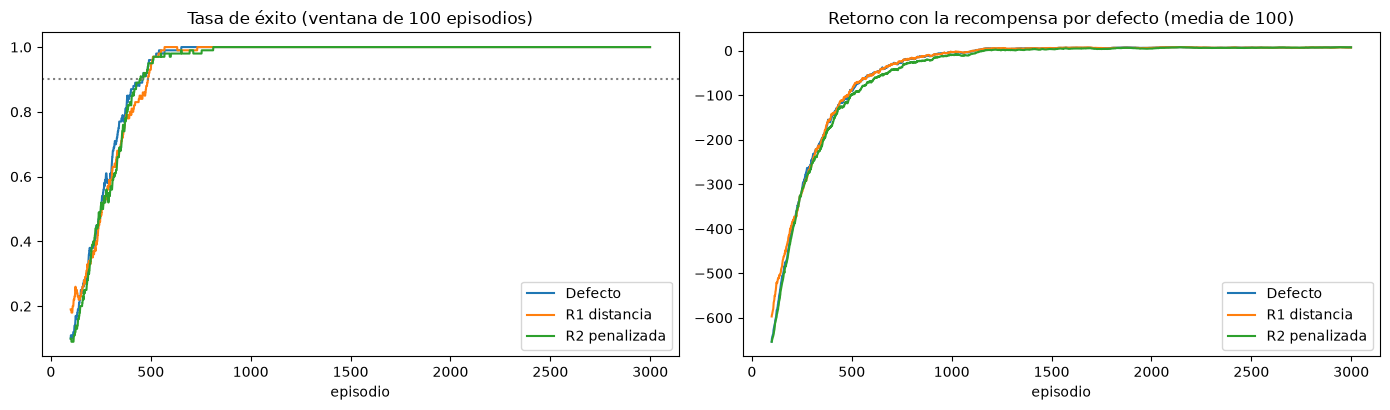

,Versión,Episodio con éxito ≥ 90 %,Desvío retorno (últimos 500),Segundos,exito greedy,retorno medio,pasos medios
0,Defecto,459,3.94,1.7,0.99,6.00,14.79
1,R1 distancia,486,4.21,1.9,1.00,8.05,12.95
2,R2 penalizada,445,3.81,1.8,0.94,-22.26,24.00


In [7]:
def media_movil(x, ventana):
    return pd.Series(x).rolling(ventana).mean().to_numpy()


def episodio_umbral(valores, umbral=0.9, ventana=100):
    """Primer episodio (desde 1) en que la media móvil de `ventana` episodios llega a `umbral`."""
    tasa = media_movil(np.asarray(valores, dtype=float), ventana)
    cruces = np.flatnonzero(tasa >= umbral)
    return int(cruces[0]) + 1 if len(cruces) else None    # número de episodio, desde 1


fig, (eje_exito, eje_retorno) = plt.subplots(1, 2, figsize=(14, 4.2))
filas = []
for nombre, (Q, historia, segundos) in resultados_taxi.items():
    eje_exito.plot(media_movil(historia["exito"].astype(float), 100), label=nombre)
    eje_retorno.plot(media_movil(historia["retorno_defecto"], 100), label=nombre)
    filas.append({"Versión": nombre, "Episodio con éxito ≥ 90 %": episodio_umbral(historia["exito"]),
                  "Desvío retorno (últimos 500)": round(float(historia["retorno_defecto"][-500:].std()), 2),
                  "Segundos": round(segundos, 1),
                  **evaluar_greedy(versiones_taxi[nombre](), Q)})
eje_exito.axhline(0.9, color="gray", ls=":")
eje_exito.set_title("Tasa de éxito (ventana de 100 episodios)")
eje_retorno.set_title("Retorno con la recompensa por defecto (media de 100)")
for eje in (eje_exito, eje_retorno):
    eje.set_xlabel("episodio")
    eje.legend()
fig.tight_layout()
fig.savefig(carpeta_figuras / "ej2_01_convergencia_recompensas.png", dpi=120, bbox_inches="tight")
plt.show()
tabla_taxi = pd.DataFrame(filas)
tabla_taxi

**¿Cuál converge más rápido? ¿Cuál es más estable?**

> **Resultado.**

| Versión | Éxito ≥ 90 % | Desvío (últimos 500) | Éxito greedy | Pasos greedy |
|---|---|---|---|---|
| Defecto | episodio 459 | 3.94 | 0.99 | 14.8 |
| R1 distancia | episodio 486 | 4.21 | 1.00 | 13.0 |
| R2 penalizada | episodio 445 | 3.81 | 0.94 | 24.0 |

- **Velocidad.** Las tres curvas casi se superponen. R2 llega al 90 % primero
  (episodio 445) y R1 último (episodio 486). La diferencia es de 41 episodios, y
  la ventana de 100 episodios tiene ese mismo orden de ruido. La velocidad la
  controla sobre todo ε: con λ = 0.995, ε baja de 1 a 0.1 en 460 episodios.
- **R1 empieza mejor.** En los primeros 100 episodios, R1 tiene 19 % de éxito y
  las otras dos 10 %. El shaping da una dirección desde el primer paso. Después
  ε domina y la ventaja desaparece. Taxi es un problema chico, y el +20 final se
  encuentra por azar en pocos episodios.
- **100 % de éxito.** R1 llega primero (episodio 570), después la recompensa por
  defecto (654) y al final R2 (814).
- **Estabilidad.** Después de la convergencia, las tres versiones tienen un desvío
  del retorno parecido (3.8 a 4.2). El desvío viene de la distancia entre el
  taxi, el pasajero y el destino, que cambia en cada episodio.
- **Política final.** R1 da la mejor política greedy: 100 % de éxito en 13.0
  pasos. R2 falla en 6 de 100 episodios.

**Por qué falla la política greedy.** En los episodios fallidos, el taxi repite
una acción que no cambia el estado: un movimiento contra una pared, o subir un
pasajero que no está. Son estados iniciales poco visitados, con valores de Q
casi empatados (por ejemplo −6.92, −6.88, −6.91 y −6.87). Durante el
entrenamiento este bucle no dura: cada repetición baja el valor de esa acción, y
ε = 0.01 agrega acciones al azar. Con la tabla congelada, el bucle sigue hasta el
límite de 200 pasos. Por eso el éxito de entrenamiento es 100 % y el greedy es
menor.

## 2.4 Análisis de convergencia y visualización

### a) y b) Retorno por episodio y tasa de éxito

Para la recompensa por defecto graficamos el retorno de cada episodio (con su
media de 100) y la tasa de éxito en ventanas de 100 episodios. La línea vertical
marca el primer episodio en el que la tasa llega a 90 %.

Durante el entrenamiento el agente explora con ε > 0. Por eso la tasa de éxito
de entrenamiento queda por debajo de la de la política greedy.

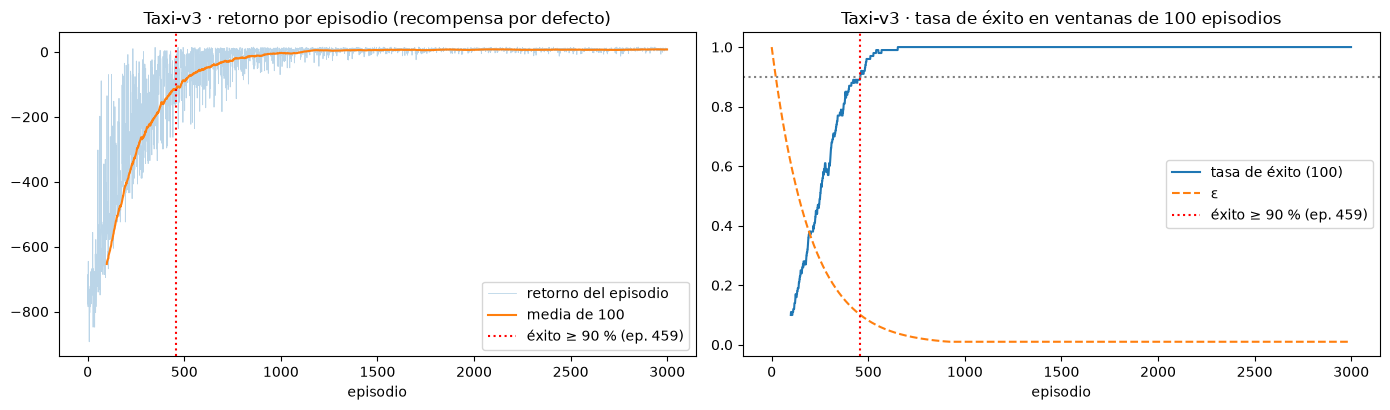

Primer episodio con tasa de éxito ≥ 90 % (ventana de 100): 459
ε en ese episodio: 0.101


In [8]:
episodio_90 = episodio_umbral(historia_defecto["exito"])
fig, (eje_r, eje_e) = plt.subplots(1, 2, figsize=(14, 4.2))
eje_r.plot(historia_defecto["retorno"], alpha=0.3, lw=0.6, label="retorno del episodio")
eje_r.plot(media_movil(historia_defecto["retorno"], 100), label="media de 100")
eje_r.set_title("Taxi-v3 · retorno por episodio (recompensa por defecto)")
eje_e.plot(media_movil(historia_defecto["exito"].astype(float), 100), label="tasa de éxito (100)")
eje_e.plot(historia_defecto["epsilon"], ls="--", label="ε")
eje_e.axhline(0.9, color="gray", ls=":")
if episodio_90:
    for eje in (eje_r, eje_e):
        eje.axvline(episodio_90, color="red", ls=":", label=f"éxito ≥ 90 % (ep. {episodio_90})")
eje_e.set_title("Taxi-v3 · tasa de éxito en ventanas de 100 episodios")
for eje in (eje_r, eje_e):
    eje.set_xlabel("episodio")
    eje.legend()
fig.tight_layout()
fig.savefig(carpeta_figuras / "ej2_02_convergencia_taxi.png", dpi=120, bbox_inches="tight")
plt.show()
print("Primer episodio con tasa de éxito ≥ 90 % (ventana de 100):", episodio_90)
print("ε en ese episodio:", round(float(historia_defecto["epsilon"][episodio_90 - 1]), 3) if episodio_90 else "-")

> **Resultado.**

- La tasa de éxito llega al 90 % en el episodio 459, con ε = 0.10. Llega al 100 %
  en el episodio 654.
- El retorno medio sube de −650 en los primeros 100 episodios a cerca de 0 en el
  episodio 1 000, y queda en +7 después. En los primeros 100 episodios, el 90 %
  llega al límite de 200 pasos, con varias acciones ilegales.
- La curva de éxito sigue a la curva de ε. Con ε alto el agente explora y falla
  aunque la tabla ya tenga una buena política. Por eso la política greedy (99 %)
  es mejor que la tasa de entrenamiento en el mismo momento.

### c) Un episodio completo del agente entrenado

El agente (`AgenteTabular`) usa la política greedy de la Q-Table entrenada con la
recompensa por defecto.
Elegimos una semilla que no se usó en el entrenamiento.

In [9]:
animacion_taxi, retorno_taxi, pasos_taxi = render_episode(
    gym.make("Taxi-v3", render_mode="rgb_array"), AgenteTabular(Q_defecto), seed=2024, titulo="Taxi-v3 entrenado")
print(f"Retorno {retorno_taxi:.0f} en {pasos_taxi} pasos")
display(animacion_taxi)

Retorno 9 en 12 pasos


> **Resultado.** El agente resuelve el episodio en 12 pasos, con retorno 9: 11 pasos de
−1 y +20 al dejar al pasajero. No hay acciones ilegales ni movimientos contra las
paredes. El taxi va al pasajero, lo sube, va al destino y lo deja.

# Ejercicio 3 — Deep Q-Learning (DQN) en LunarLander-v3

## 3.1 Análisis del MDP y motivación del DQN

La celda muestra los espacios del entorno y hace tres pruebas:

1. Episodios con una política aleatoria, para medir la frecuencia y la magnitud
   de las recompensas.
2. Dos episodios con la misma semilla y las mismas acciones, para ver si el
   entorno es determinista.
3. Dos `reset` con semillas distintas, para ver qué parte es aleatoria.

In [10]:
env_lunar = gym.make("LunarLander-v3")
print("Estados:", env_lunar.observation_space)
print("Acciones:", env_lunar.action_space, "| límite de pasos:", env_lunar.spec.max_episode_steps)

# 1. Política aleatoria
recompensas_paso, retornos_aleatorio, largos_aleatorio, finales = [], [], [], []
for i in range(5 if SMOKE else 50):
    obs, _ = env_lunar.reset(seed=1000 + i)
    terminado = truncado = False
    retorno, pasos = 0.0, 0
    while not (terminado or truncado):
        obs, r, terminado, truncado, _ = env_lunar.step(env_lunar.action_space.sample())
        recompensas_paso.append(r)
        retorno += r
        pasos += 1
    finales.append(r)
    retornos_aleatorio.append(retorno)
    largos_aleatorio.append(pasos)
recompensas_paso = np.array(recompensas_paso)
print(f"Política aleatoria: retorno {np.mean(retornos_aleatorio):.1f} ± {np.std(retornos_aleatorio):.1f}, "
      f"{np.mean(largos_aleatorio):.0f} pasos por episodio")
print(f"Recompensa por paso: mediana {np.median(recompensas_paso):.2f}, "
      f"percentiles 1-99 [{np.percentile(recompensas_paso, 1):.2f}, {np.percentile(recompensas_paso, 99):.2f}]")
print(f"Recompensa del último paso: media {np.mean(finales):.1f} (-100 = choque)")

# 2. Misma semilla y mismas acciones
acciones_fijas = np.random.default_rng(0).integers(0, 4, 200)
trayectorias = []
for _ in range(2):
    obs, _ = env_lunar.reset(seed=7)
    estados = [obs]
    for a in acciones_fijas:
        obs, _, terminado, truncado, _ = env_lunar.step(int(a))
        estados.append(obs)
        if terminado or truncado:
            break
    trayectorias.append(np.array(estados))
print("Misma semilla y mismas acciones -> trayectorias idénticas:",
      np.array_equal(trayectorias[0], trayectorias[1]))

# 3. Semillas distintas
print("Estado inicial con seed=1:", np.round(env_lunar.reset(seed=1)[0], 3))
print("Estado inicial con seed=2:", np.round(env_lunar.reset(seed=2)[0], 3))

Estados: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Acciones: Discrete(4) | límite de pasos: 1000


Política aleatoria: retorno -211.9 ± 124.0, 96 pasos por episodio
Recompensa por paso: mediana -1.36, percentiles 1-99 [-100.00, 6.89]
Recompensa del último paso: media -100.0 (-100 = choque)
Misma semilla y mismas acciones -> trayectorias idénticas: True
Estado inicial con seed=1: [-0.003  1.417 -0.275  0.284  0.003  0.062  0.     0.   ]
Estado inicial con seed=2: [-1.000e-03  1.414e+00 -1.090e-01  1.550e-01  1.000e-03  2.500e-02
  0.000e+00  0.000e+00]


**a) Estado y acciones.** El estado tiene 8 componentes:

| # | Componente | Tipo |
|---|---|---|
| 0, 1 | Posición $x$, $y$ relativa a la plataforma | continuo |
| 2, 3 | Velocidad lineal $v_x$, $v_y$ | continuo |
| 4 | Ángulo de la nave | continuo |
| 5 | Velocidad angular | continuo |
| 6, 7 | Contacto de la pata izquierda y de la derecha con el suelo | booleano (0 o 1) |

Las 4 acciones son: no hacer nada, encender el motor de orientación izquierdo,
encender el motor principal y encender el motor de orientación derecho.

**b) Recompensas.** El entorno da una recompensa en **cada paso**:

- un término de *shaping* que sube cuando la nave se acerca a la plataforma, baja
  la velocidad y queda horizontal, y baja en el caso contrario;
- +10 por cada pata que toca el suelo;
- −0.3 por cada frame con el motor principal encendido y −0.03 por cada frame
  con un motor lateral;
- al final, −100 si la nave choca o sale de la pantalla, o +100 si aterriza y
  queda quieta.

Un episodio con retorno ≥ 200 cuenta como resuelto. La política aleatoria da un
retorno de −211.9 ± 124.0 en 96 pasos de media. La mediana de la recompensa por
paso es −1.36, y el 98 % de los pasos está entre −100 y +6.9. El último paso da
siempre −100: todos los episodios aleatorios terminan con un choque. El retorno
depende sobre todo de ese evento final.

**c) Determinismo y tipo de tarea.** Con la misma semilla y las mismas acciones,
las dos trayectorias son idénticas: la física es determinista. Con semillas
distintas cambian el terreno y la velocidad inicial (por ejemplo $v_x = -0.275$
con `seed=1` y $-0.109$ con `seed=2`), porque el entorno aplica una fuerza
inicial al azar. Para el agente, el MDP es estocástico en el estado inicial y
determinista en las transiciones.
La tarea es **episódica**: termina con un choque, con un aterrizaje o con el
límite de 1000 pasos.

### d) a g) ¿Por qué Q-Learning clásico no es viable acá?

Si cada una de las 8 variables se divide en $k$ bins uniformes, hay $k^8$
estados. La celda calcula la cantidad de estados, las entradas de la Q-Table con
4 acciones y la memoria con `float32` (4 bytes por entrada).

In [11]:
filas = [{"Problema": "Taxi-v3", "Estados": 500, "Entradas Q-Table": 500 * 6, "Memoria float32": "12 KB"}]
# Supuesto del enunciado: las 8 variables con k bins. Variante: las 2 patas son booleanas (2 valores)
for k in (10, 20):
    for nombre, estados in ((f"LunarLander, k = {k} (8 variables)", k ** 8),
                            (f"LunarLander, k = {k} (6 continuas, 2 patas)", 4 * k ** 6)):
        filas.append({"Problema": nombre, "Estados": f"{estados:.3e}", "Entradas Q-Table": f"{estados * 4:.3e}",
                      "Memoria float32": f"{estados * 4 * 4 / 1e9:,.3f} GB"})
filas.append({"Problema": "Red Q del DQN (8-128-128-4)", "Estados": "continuo",
              "Entradas Q-Table": "-", "Memoria float32": f"{(8*128 + 128 + 128*128 + 128 + 128*4 + 4) * 4 / 1e3:.0f} KB"})
pd.DataFrame(filas)

,Problema,Estados,Entradas Q-Table,Memoria float32
0,Taxi-v3,500,3000,12 KB
1,"LunarLander, k = 10 (8 variables)",1.000e+08,4.000e+08,1.600 GB
2,"LunarLander, k = 10 (6 continuas, 2 patas)",4.000e+06,1.600e+07,0.064 GB
3,"LunarLander, k = 20 (8 variables)",2.560e+10,1.024e+11,409.600 GB
4,"LunarLander, k = 20 (6 continuas, 2 patas)",2.560e+08,1.024e+09,4.096 GB
5,Red Q del DQN (8-128-128-4),continuo,-,73 KB


**d) y e)** Con $k = 10$ hay $10^8$ estados y $4 \times 10^8$ entradas (1.6 GB).
Con $k = 20$ hay $2.56 \times 10^{10}$ estados y $1.024 \times 10^{11}$ entradas
(410 GB).

**f)** La Q-Table de Taxi tiene 3 000 entradas. Con $k = 10$, la de LunarLander
tiene 133 000 veces más, y con $k = 20$, 34 millones de veces más. El problema no
es solo la memoria. Cada entrada se aprende solo si el agente visita ese par
$(s, a)$ muchas veces. Con $k = 10$, un entrenamiento de un millón de pasos visita
como máximo el 1 % de los estados. El fenómeno se llama **maldición de la dimensionalidad** (*curse of
dimensionality*, Bellman). El número de celdas crece de forma exponencial con la
cantidad de dimensiones, y los datos necesarios para llenarlas también.

Además, los bins son una aproximación mala para este problema. Dos estados en
bins vecinos son casi iguales, pero la tabla los trata como independientes.

Las patas son booleanas y solo necesitan 2 valores. Con esa corrección hay
$4 k^6$ estados: $4 \times 10^6$ con $k = 10$ (64 MB de tabla) y $2.56 \times 10^8$
con $k = 20$ (4.1 GB). La tabla de $k = 10$ entra en memoria, pero tiene 5 300 veces
más entradas que la de Taxi, y la conclusión no cambia: el agente no puede visitar
todas las celdas suficientes veces.

**g)** Una red neuronal $Q(s, a; \theta)$ recibe el vector continuo y devuelve los
4 valores Q en una pasada. La red del DQN de este notebook tiene 18 180
parámetros (73 KB), sin importar $k$. La ventaja concreta es la
**generalización**: una actualización para un estado cambia también los valores
de los estados parecidos, porque comparten los pesos. El agente puede estimar el
valor de un estado que nunca visitó.

## 3.2 Ablación: impacto de Experience Replay y Target Network

### Implementación del DQN

Una sola función entrena las tres versiones. Dos banderas eligen la versión:

| Versión | `usar_replay` | `usar_target` | Batch de entrenamiento | Objetivo TD |
|---|---|---|---|---|
| (a) DQN base | No | No | Las últimas 64 transiciones consecutivas | Red online |
| (b) DQN + ER | Sí | No | 64 transiciones al azar del buffer | Red online |
| (c) DQN completo | Sí | Sí | 64 transiciones al azar del buffer | Target network, copia cada 1000 pasos |

La versión (a) usa el mismo tamaño de batch que (b) y (c), y también entrena en
cada paso. La única diferencia es la **correlación** entre las muestras. Así se
cumple la regla del enunciado de usar hiperparámetros idénticos.

Hiperparámetros comunes:

| Parámetro | Valor | Motivo |
|---|---|---|
| Red | MLP 8 → 128 → 128 → 4, ReLU | Suficiente para 8 entradas. Tiene 18 180 parámetros |
| Optimizador | Adam, lr = 5e-4 | Valor habitual para LunarLander |
| $\gamma$ | 0.99 | Las recompensas importantes (aterrizaje, choque) llegan al final |
| Batch | 64 | |
| Buffer | 100 000 transiciones | Unos 100 a 300 episodios de experiencia |
| Inicio del entrenamiento | después de 1 000 pasos | El buffer tiene datos variados antes del primer batch |
| ε | de 1.0 a 0.01, × 0.995 por episodio | ε = 0.37 en el episodio 200 y 0.13 en el 400 |
| Target network | copia completa cada 1 000 pasos de optimización | La copia cada $C$ pasos del apunte |
| Pérdida | MSE, con gradient clipping de norma 10 | El MSE es la pérdida del apunte |

El objetivo TD usa $(1 - \text{terminado})$. Un episodio truncado a los 1 000
pasos no es terminal, así que su estado siguiente conserva su valor.

Además de la loss, guardamos el **Q medio** del batch en cada paso. Si la red
diverge, el Q medio crece sin límite. Un retorno real no supera unos 300 puntos.

El DQN corre en CPU, aun en Colab. La red es chica y se entrena con un batch por
paso del entorno. Mover 64 vectores a la GPU en cada paso cuesta más que el
cálculo.

In [12]:
dispositivo_dqn = torch.device("cpu")
torch.set_num_threads(2)

CONFIG_DQN = dict(lr=5e-4, gamma=0.99, batch_size=64, capacidad_buffer=100_000, pasos_inicio=1_000,
                  eps_inicio=1.0, eps_min=0.01, decaimiento=0.995, sincronizar_cada=1_000,
                  ocultas=128, usar_replay=True, usar_target=True)


class QNetwork(nn.Module):
    def __init__(self, dim_estado, n_acciones, ocultas=128):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(dim_estado, ocultas), nn.ReLU(),
            nn.Linear(ocultas, ocultas), nn.ReLU(),
            nn.Linear(ocultas, n_acciones),
        )

    def forward(self, x):
        return self.red(x)


class ReplayBuffer:
    """Buffer circular en arreglos de NumPy, para poder guardarlo en el checkpoint."""

    def __init__(self, capacidad, dim_estado):
        self.estados = np.zeros((capacidad, dim_estado), np.float32)
        self.siguientes = np.zeros((capacidad, dim_estado), np.float32)
        self.acciones = np.zeros(capacidad, np.int64)
        self.recompensas = np.zeros(capacidad, np.float32)
        self.terminados = np.zeros(capacidad, np.float32)
        self.capacidad, self.posicion, self.tamano = capacidad, 0, 0

    def agregar(self, s, a, r, s_sig, terminado):
        i = self.posicion
        self.estados[i], self.acciones[i], self.recompensas[i] = s, a, r
        self.siguientes[i], self.terminados[i] = s_sig, terminado
        self.posicion = (i + 1) % self.capacidad
        self.tamano = min(self.tamano + 1, self.capacidad)

    def indices_aleatorios(self, n, rng):
        return rng.integers(0, self.tamano, n)              # (b) y (c): muestras al azar

    def indices_ultimos(self, n):
        return (self.posicion - 1 - np.arange(n)) % self.capacidad   # (a): las n más recientes

    def batch(self, indices):
        return [torch.from_numpy(x[indices]) for x in
                (self.estados, self.acciones, self.recompensas, self.siguientes, self.terminados)]

    def a_dict(self):
        return dict(vars(self))

    def desde_dict(self, d):
        vars(self).update(d)


def accion_greedy(red, obs):
    with torch.no_grad():
        return int(red(torch.as_tensor(obs, dtype=torch.float32)).argmax())


def paso_optimizacion(red, red_objetivo, optimizador, batch, gamma):
    estados, acciones, recompensas, siguientes, terminados = batch
    q_actual = red(estados).gather(1, acciones[:, None]).squeeze(1)
    with torch.no_grad():
        q_siguiente = red_objetivo(siguientes).max(dim=1).values
        objetivo = recompensas + gamma * (1 - terminados) * q_siguiente
    loss = F.mse_loss(q_actual, objetivo)
    optimizador.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(red.parameters(), 10.0)
    optimizador.step()
    return loss.item(), q_actual.mean().item()


class AgenteDQN:
    """Política greedy de una red Q, para render_episode."""

    def __init__(self, red):
        self.red = red.eval()

    def select_action(self, obs):
        return accion_greedy(self.red, obs)

Las piezas del DQN están listas: la red, el buffer con sus dos formas de muestreo
y el paso de optimización. Con `red_objetivo = red`, el mismo paso da la versión
sin target network.

### Loop de entrenamiento con checkpoints

El loop guarda un checkpoint cada 25 episodios y al final. El checkpoint tiene la
red, la target network, el optimizador, el buffer completo, el estado del
generador aleatorio y el historial. Si el archivo existe, el entrenamiento sigue
desde el episodio siguiente. Si ya terminó, solo se cargan los resultados.

Parámetros del loop:

- `max_episodios`: el límite de episodios.
- `umbral`: si no es `None`, el entrenamiento se detiene cuando la media de los
  últimos 100 episodios llega al umbral.

La condición de parada se calcula en cada episodio con estos argumentos y con el
historial. No se guarda en el checkpoint. Así, retomar el mismo experimento y
seguir a otro experimento con `continuar_de` son el mismo camino.
- `guardar_en`: episodios en los que se guardan los pesos, antes de jugar ese
  episodio. Por defecto son 0 (agente sin entrenar) y 200, los momentos que pide
  la sección 3.3. Cada copia ocupa 73 KB.
- `continuar_de`: checkpoint de otro experimento con la misma configuración. El
  entrenamiento empieza desde ese punto.

In [13]:
def entrenar_dqn(nombre, cfg, max_episodios, umbral=None, guardar_en=(0, 200), continuar_de=None, semilla=42):
    ruta = carpeta_ckpt / f"{nombre}.pth"
    set_seed(semilla)
    env = gym.make("LunarLander-v3")
    env.action_space.seed(semilla)
    dim_estado, n_acciones = env.observation_space.shape[0], env.action_space.n
    red = QNetwork(dim_estado, n_acciones, cfg["ocultas"]).to(dispositivo_dqn)
    red_target = QNetwork(dim_estado, n_acciones, cfg["ocultas"]).to(dispositivo_dqn)
    red_target.load_state_dict(red.state_dict())
    optimizador = torch.optim.Adam(red.parameters(), lr=cfg["lr"])
    buffer = ReplayBuffer(cfg["capacidad_buffer"], dim_estado)
    rng = np.random.default_rng(semilla)
    estado = {"episodio": 0, "pasos": 0, "optimizaciones": 0, "segundos": 0.0,
              "historia": {"retorno": [], "pasos": [], "epsilon": [], "loss": [], "q_medio": []},
              "pesos_guardados": {}}
    historia = estado["historia"]

    def debe_seguir():
        convergio = umbral is not None and episodio_umbral(historia["retorno"], umbral, 100) is not None
        return estado["episodio"] < max_episodios and not convergio

    origen = ruta if ruta.exists() else continuar_de
    if origen is not None and Path(origen).exists():
        checkpoint = torch.load(origen, map_location=dispositivo_dqn, weights_only=False)
        red.load_state_dict(checkpoint["model_state_dict"])
        red_target.load_state_dict(checkpoint["target_state_dict"])
        optimizador.load_state_dict(checkpoint["optimizer_state_dict"])
        buffer.desde_dict(checkpoint["buffer"])
        rng.bit_generator.state = checkpoint["rng"]
        estado = checkpoint["estado"]
        historia = estado["historia"]
        print(f"{nombre}: {'se retoma' if debe_seguir() else 'terminado'} en el episodio {estado['episodio']} "
              f"(desde {Path(origen).name})")

    def guardar():
        torch.save({"epoch": estado["episodio"], "model_state_dict": red.state_dict(),
                    "target_state_dict": red_target.state_dict(),
                    "optimizer_state_dict": optimizador.state_dict(),
                    "loss": estado["historia"]["loss"][-1] if estado["historia"]["loss"] else None,
                    "buffer": buffer.a_dict(), "rng": rng.bit_generator.state, "cfg": cfg, "estado": estado}, ruta)

    red_objetivo = red_target if cfg["usar_target"] else red
    inicio = time.time() - estado["segundos"]
    while debe_seguir():
        episodio = estado["episodio"]
        if episodio in guardar_en:
            estado["pesos_guardados"][episodio] = {k: v.clone() for k, v in red.state_dict().items()}
        epsilon = max(cfg["eps_min"], cfg["eps_inicio"] * cfg["decaimiento"] ** episodio)
        obs, _ = env.reset(seed=semilla + episodio)
        retorno, pasos_episodio, fin = 0.0, 0, False
        while not fin:
            # ε-greedy
            accion = int(rng.integers(n_acciones)) if rng.random() < epsilon else accion_greedy(red, obs)
            siguiente, recompensa, terminado, truncado, _ = env.step(accion)
            buffer.agregar(obs, accion, recompensa, siguiente, float(terminado))
            obs, retorno, fin = siguiente, retorno + recompensa, terminado or truncado
            estado["pasos"] += 1
            pasos_episodio += 1
            # Un paso de optimización por paso del entorno, después del inicio
            if estado["pasos"] >= cfg["pasos_inicio"]:
                indices = (buffer.indices_aleatorios(cfg["batch_size"], rng) if cfg["usar_replay"]
                           else buffer.indices_ultimos(cfg["batch_size"]))
                loss, q_medio = paso_optimizacion(red, red_objetivo, optimizador, buffer.batch(indices), cfg["gamma"])
                historia["loss"].append(loss)
                historia["q_medio"].append(q_medio)
                estado["optimizaciones"] += 1
                if cfg["usar_target"] and estado["optimizaciones"] % cfg["sincronizar_cada"] == 0:
                    red_target.load_state_dict(red.state_dict())
        historia["retorno"].append(retorno)
        historia["pasos"].append(pasos_episodio)
        historia["epsilon"].append(epsilon)
        estado["episodio"] = episodio + 1
        estado["segundos"] = time.time() - inicio
        if estado["episodio"] % 25 == 0 or not debe_seguir():
            guardar()
            print(f"{nombre} ep {estado['episodio']:4d} | media 100: {np.mean(historia['retorno'][-100:]):7.1f} | ε {epsilon:.3f} | "
                  f"pasos {estado['pasos']:7d} | {estado['segundos'] / 60:.1f} min")
    estado["pesos_guardados"]["final"] = {k: v.clone() for k, v in red.state_dict().items()}
    return red, estado


EPISODIOS_ABLACION = 3 if SMOKE else 400
versiones_dqn = {
    "a_base": {"usar_replay": False, "usar_target": False},
    "b_replay": {"usar_replay": True, "usar_target": False},
    "c_completo": {"usar_replay": True, "usar_target": True},
}
resultados_ablacion = {}
for nombre, banderas in versiones_dqn.items():
    resultados_ablacion[nombre] = entrenar_dqn(f"dqn_{nombre}", {**CONFIG_DQN, **banderas}, EPISODIOS_ABLACION)

dqn_a_base: terminado en el episodio 400 (desde dqn_a_base.pth)
dqn_b_replay: terminado en el episodio 400 (desde dqn_b_replay.pth)
dqn_c_completo: terminado en el episodio 400 (desde dqn_c_completo.pth)


Las tres versiones completaron los mismos 400 episodios con los mismos
hiperparámetros. Los checkpoints quedan en Drive. Una nueva ejecución del
notebook solo los carga.

### Gráficos de la ablación

- **a)** Retorno por episodio con media móvil de 20 episodios.
- **b)** Loss por paso de optimización. La loss tiene mucho ruido, así que
  graficamos también una media móvil de 1 000 pasos. El eje es logarítmico.
- Q medio del batch por paso de optimización, para ver si la red diverge.

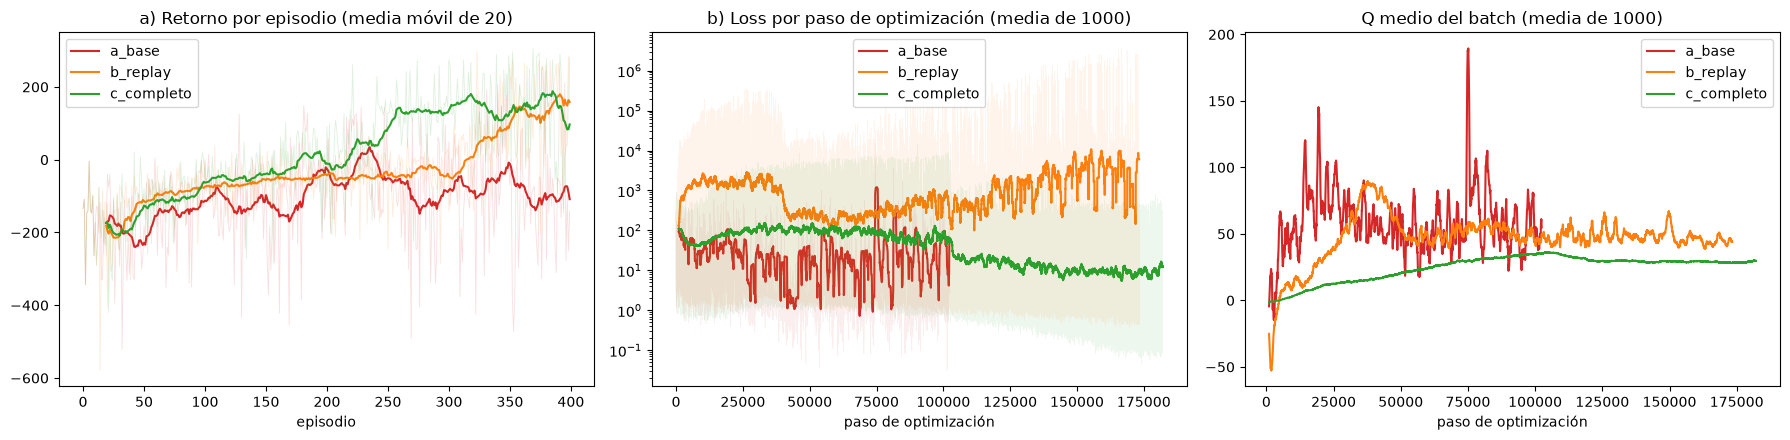

,Versión,Retorno medio (últimos 100),Mejor media de 20,Loss media (último 10 %),Q medio final,Pasos del entorno,Minutos
0,a_base,-83.1,34.4,37.64,54.8,103433,2.4
1,b_replay,99.0,179.9,3529.37,43.9,174279,6.2
2,c_completo,140.4,188.2,9.22,29.7,183056,6.0


In [14]:
colores = {"a_base": "tab:red", "b_replay": "tab:orange", "c_completo": "tab:green"}
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.5))
filas = []
for nombre, (_, estado) in resultados_ablacion.items():
    historia = estado["historia"]
    retornos = np.array(historia["retorno"])
    ejes[0].plot(retornos, color=colores[nombre], alpha=0.15, lw=0.6)
    ejes[0].plot(media_movil(retornos, 20), color=colores[nombre], label=nombre)
    loss = np.array(historia["loss"])
    ejes[1].plot(loss, color=colores[nombre], alpha=0.08, lw=0.4)
    ejes[1].plot(media_movil(loss, 1000), color=colores[nombre], label=nombre)
    ejes[2].plot(media_movil(np.array(historia["q_medio"]), 1000), color=colores[nombre], label=nombre)
    filas.append({"Versión": nombre,
                  "Retorno medio (últimos 100)": round(float(retornos[-100:].mean()), 1),
                  "Mejor media de 20": round(float(np.nanmax(media_movil(retornos, 20))) if len(retornos) >= 20 else float("nan"), 1),
                  "Loss media (último 10 %)": round(float(loss[-max(1, len(loss) // 10):].mean()), 2) if len(loss) else None,
                  "Q medio final": round(float(np.mean(historia["q_medio"][-1000:])), 1) if historia["q_medio"] else None,
                  "Pasos del entorno": estado["pasos"],
                  "Minutos": round(estado["segundos"] / 60, 1)})
ejes[0].set_title("a) Retorno por episodio (media móvil de 20)")
ejes[0].set_xlabel("episodio")
ejes[1].set_yscale("log")
ejes[1].set_title("b) Loss por paso de optimización (media de 1000)")
ejes[1].set_xlabel("paso de optimización")
ejes[2].set_title("Q medio del batch (media de 1000)")
ejes[2].set_xlabel("paso de optimización")
for eje in ejes:
    eje.legend()
fig.tight_layout()
fig.savefig(carpeta_figuras / "ej3_01_ablacion.png", dpi=120, bbox_inches="tight")
plt.show()
tabla_ablacion = pd.DataFrame(filas)
tabla_ablacion

> **Resultado.**

| Versión | Retorno medio (últimos 100) | Mejor media de 20 | Loss media (último 10 %) | Q medio final | Episodios negativos (últimos 100) |
|---|---|---|---|---|---|
| (a) base | −83.1 | 34.4 | 37.6 | 54.8 | 70 % |
| (b) + ER | 99.0 | 179.9 | 3 529 | 43.9 | 17 % |
| (c) completo | 140.4 | 188.2 | 9.2 | 29.7 | 8 % |

**c) ¿En qué versiones aparece el *moving target*? ¿Cómo se ve en la curva de
loss?**

Aparece en (a) y en (b). Las dos calculan el objetivo TD con la red online, que
cambia en cada paso. Cada actualización mueve también el objetivo de la próxima.

- En (b), la loss sube de $10^2$-$10^3$ a $10^4$ después del paso 100 000, con picos
  de $10^6$. Al final es 380 veces la loss de (c). La red persigue un objetivo que
  ella misma mueve.
- En (a), la loss es la más baja (1 a 100), pero no indica un buen aprendizaje. Las
  64 transiciones consecutivas son casi iguales, y la red las ajusta fácil. El
  síntoma está en Q: el Q medio de (a) tiene picos de 145 y 190, cuando el retorno
  real está entre −200 y 0.
- En (c), la loss queda entre 10 y 100, y el Q medio sube suave hasta cerca de 30.

**d) ¿Por qué la correlación temporal perjudica a la versión (a), y cómo la
resuelve el Experience Replay en la versión (b)?**

El batch de (a) son los últimos 64 pasos de un mismo episodio: estados casi
iguales, con las mismas acciones. Las muestras no son independientes, y el
gradiente empuja a la red hacia la parte de la trayectoria que está viendo. La
red olvida lo que aprendió en otras zonas del estado. Por eso el retorno de (a)
oscila y no mejora: −83 de media al final y 70 % de episodios negativos.

El buffer de (b) guarda 100 000 transiciones de cientos de episodios. Un batch al
azar mezcla estados de zonas y momentos distintos, así que las muestras son casi
independientes. Además, cada transición se usa muchas veces. Con el mismo tamaño
de batch, (b) llega a una media de 99.

**e) ¿Qué agrega la Target Network sobre la versión (b)? ¿Por qué no alcanza con
el Experience Replay?**

El Experience Replay quita la correlación entre las muestras, pero no el *moving
target*. En (b), un error en $Q(s')$ entra en el objetivo, y la actualización lo
pasa a $Q(s)$ con los mismos pesos. Este lazo hace crecer la loss.

La target network fija el objetivo durante 1 000 pasos. En ese tiempo, el
problema es una regresión con un objetivo fijo, como en el aprendizaje
supervisado. Resultado: la loss de (c) es estable, el Q medio no tiene picos, y
el retorno final es mejor (140 contra 99) con la mitad de episodios negativos (8 %
contra 17 %). La mejor media de 20 es parecida en (b) y en (c). La diferencia está
en la estabilidad, no en el máximo.

## 3.3 Entrenamiento completo y visualización

El DQN completo es la versión (c). Seguimos su entrenamiento desde el episodio
400 de la ablación, en lugar de empezar de cero. La configuración y la semilla
son las mismas, así que los primeros 400 episodios de un entrenamiento nuevo
serían idénticos a los de (c). Esto ahorra unos 15 minutos de Colab.

El entrenamiento se detiene cuando la media de los últimos 100 episodios llega
a 200, o en el episodio 1 500.

Reportamos:

- el primer episodio en el que la **media móvil de 50** cruza 0;
- el **episodio de convergencia**: el primero en el que la media de los últimos
  100 episodios es ≥ 200.

dqn_completo: terminado en el episodio 534 (desde dqn_completo.pth)


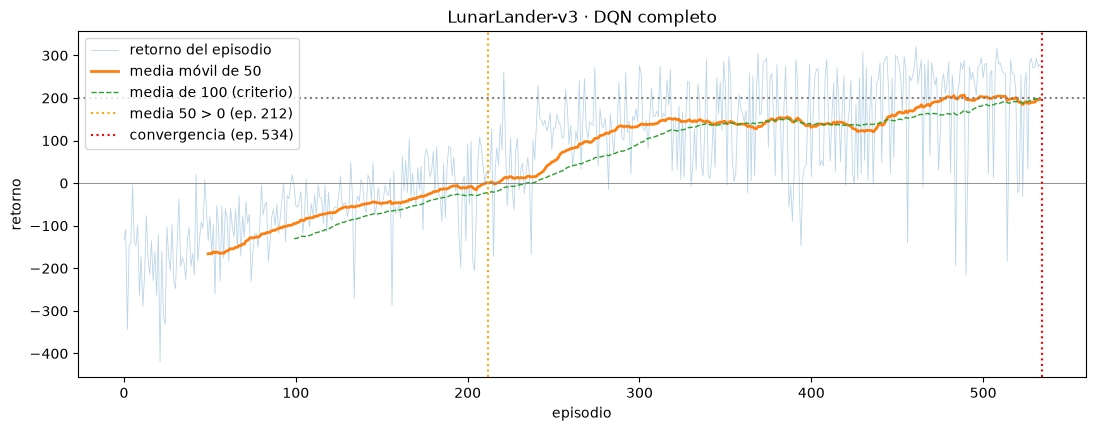

Primer episodio con media móvil de 50 > 0: 212
Episodio de convergencia (media de 100 ≥ 200): 534
Pasos del entorno: 238,293 | tiempo total: 7.8 min


In [15]:
MAX_EPISODIOS_COMPLETO = 6 if SMOKE else 1500
red_completa, estado_completo = entrenar_dqn(
    "dqn_completo", CONFIG_DQN, MAX_EPISODIOS_COMPLETO, umbral=200,
    continuar_de=carpeta_ckpt / "dqn_c_completo.pth")

retornos_completo = np.array(estado_completo["historia"]["retorno"])
media_50 = media_movil(retornos_completo, 50)
cruces_cero = np.flatnonzero(media_50 > 0)
episodio_cero = int(cruces_cero[0]) + 1 if len(cruces_cero) else None
media_100 = media_movil(retornos_completo, 100)
episodio_convergencia = episodio_umbral(retornos_completo, umbral=200, ventana=100)

fig, eje = plt.subplots(figsize=(13, 4.5))
eje.plot(retornos_completo, alpha=0.3, lw=0.6, label="retorno del episodio")
eje.plot(media_50, lw=2, label="media móvil de 50")
eje.plot(media_100, lw=1, ls="--", label="media de 100 (criterio)")
eje.axhline(200, color="gray", ls=":")
eje.axhline(0, color="gray", lw=0.6)
if episodio_cero:
    eje.axvline(episodio_cero, color="orange", ls=":", label=f"media 50 > 0 (ep. {episodio_cero})")
if episodio_convergencia:
    eje.axvline(episodio_convergencia, color="red", ls=":", label=f"convergencia (ep. {episodio_convergencia})")
eje.set_xlabel("episodio")
eje.set_ylabel("retorno")
eje.set_title("LunarLander-v3 · DQN completo")
eje.legend()
fig.savefig(carpeta_figuras / "ej3_02_dqn_completo.png", dpi=120, bbox_inches="tight")
plt.show()
print("Primer episodio con media móvil de 50 > 0:", episodio_cero)
print("Episodio de convergencia (media de 100 ≥ 200):", episodio_convergencia or "no convergió")
print(f"Pasos del entorno: {estado_completo['pasos']:,} | tiempo total: {estado_completo['segundos'] / 60:.1f} min")

> **Resultado.**

- La media móvil de 50 cruza 0 en el **episodio 212**.
- La media de 100 llega a 200 en el **episodio 534**: 238 293 pasos del entorno y
  7.8 minutos en CPU.
- La curva sube de forma continua hasta el episodio 300 y tiene una meseta cerca
  de 140 entre los episodios 300 y 450. Después sube otra vez hasta 200.
- En los últimos 100 episodios, el 74 % tiene retorno ≥ 200, el 9 % es negativo y el
  5 % llega al límite de 1 000 pasos. El retorno de cada episodio todavía cae a
  −100 o −200 cerca del final.

### c), d) y e) Evolución del agente

Jugamos un episodio completo con los pesos de tres momentos: el episodio 0 (sin
entrenar), el episodio 200 (en aprendizaje) y el episodio de convergencia. Los
tres episodios usan la misma semilla, así que la nave parte del mismo estado y
el terreno es el mismo. La política es greedy (ε = 0).

Los pesos del episodio 0 son los pesos iniciales al azar de la red. Una red al
azar no es una política uniforme: elige casi siempre la misma acción. El
enunciado dice "comportamiento aleatorio", así que mostramos también un episodio
con acciones al azar.

In [16]:
class AgenteAleatorio:
    def __init__(self, env):
        self.env = env

    def select_action(self, obs):
        return self.env.action_space.sample()


def red_con_pesos(pesos):
    red = QNetwork(8, 4, CONFIG_DQN["ocultas"])
    red.load_state_dict(pesos)
    return red


SEMILLA_VISUAL = 123
pesos_guardados = estado_completo["pesos_guardados"]
momentos = [("Episodio 0 · acciones al azar", AgenteAleatorio)]
for clave, titulo in ((0, "Episodio 0 · red sin entrenar"), (200, "Episodio 200 · en aprendizaje"),
                      ("final", f"Episodio {estado_completo['episodio']} · entrenado")):
    if clave in pesos_guardados:   # en el modo de prueba no se llega al episodio 200
        momentos.append((titulo, lambda env, pesos=pesos_guardados[clave]: AgenteDQN(red_con_pesos(pesos))))
for titulo, crear_agente in momentos:
    env_visual = gym.make("LunarLander-v3", render_mode="rgb_array")
    env_visual.action_space.seed(0)
    animacion, retorno, pasos = render_episode(env_visual, crear_agente(env_visual), seed=SEMILLA_VISUAL,
                                               cada=5, titulo=titulo)
    print(f"{titulo}: retorno {retorno:.1f} en {pasos} pasos")
    display(animacion)

Episodio 0 · acciones al azar: retorno -166.2 en 73 pasos


Episodio 0 · red sin entrenar: retorno -202.2 en 57 pasos


Episodio 200 · en aprendizaje: retorno 167.5 en 485 pasos


Episodio 534 · entrenado: retorno 293.6 en 207 pasos


**¿Qué aprende primero el agente? ¿Qué errores persisten hasta el final?**

> **Resultado.**

| Pesos | Retorno | Pasos | Comportamiento |
|---|---|---|---|
| Acciones al azar | −166.2 | 73 | Cae girando y choca |
| Episodio 0 (red sin entrenar) | −202.2 | 57 | Usa casi siempre un motor lateral, gira, se desplaza a la derecha y choca |
| Episodio 200 | 167.5 | 485 | Frena con el motor principal, baja muy despacio y aterriza fuera de la plataforma, a la derecha de la bandera |
| Episodio 534 | 293.6 | 207 | Baja directo, corrige la posición y aterriza entre las banderas |

- **Primero** aprende a no chocar: frenar la caída con el motor principal y
  mantener la nave horizontal. El shaping de cada paso premia la velocidad baja y
  el ángulo chico, así que esta señal llega antes.
- **Después** aprende a apoyar las patas (+10 cada una) y a quedar quieto (+100).
- **Al final** aprende la precisión: aterrizar entre las banderas y usar menos
  combustible. El episodio 534 aterriza en 207 pasos, contra 485 del episodio 200.
- **Errores que persisten.** En los últimos 100 episodios, el 9 % termina con
  retorno negativo (choques o salidas de la pantalla), y el 5 % flota hasta el
  límite de 1 000 pasos. El desvío del retorno en los últimos 100 episodios es
  121.6. La exploración (ε = 0.07 al final) explica parte de los errores.

## 3.4 Sensibilidad a hiperparámetros

Comparamos el DQN completo con dos configuraciones nuevas. Cada una cambia dos
parámetros:

| Configuración | Cambios | Pregunta |
|---|---|---|
| Base | lr = 5e-4, γ = 0.99, batch 64, copia cada 1 000 pasos | Referencia (sección 3.3) |
| A | lr = 2.5e-3 (× 5) y copia cada 250 pasos (÷ 4) | ¿Aprender más rápido desestabiliza? |
| B | γ = 0.95 y batch 128 | ¿Un horizonte corto alcanza para aterrizar? |

Las dos configuraciones entrenan desde cero, con la misma semilla que la base.
El límite es de 600 episodios por configuración, por el tiempo disponible. Si no
llegan al umbral, lo indicamos. Para comparar en la misma escala, la base se
muestra también en sus primeros 600 episodios, con la misma regla de convergencia.
Si la base converge después del episodio 600, su episodio de convergencia está en
la sección 3.3.

dqn_A_lr_alto_sync_rapida: terminado en el episodio 600 (desde dqn_A_lr_alto_sync_rapida.pth)
dqn_B_gamma095_batch128: terminado en el episodio 600 (desde dqn_B_gamma095_batch128.pth)


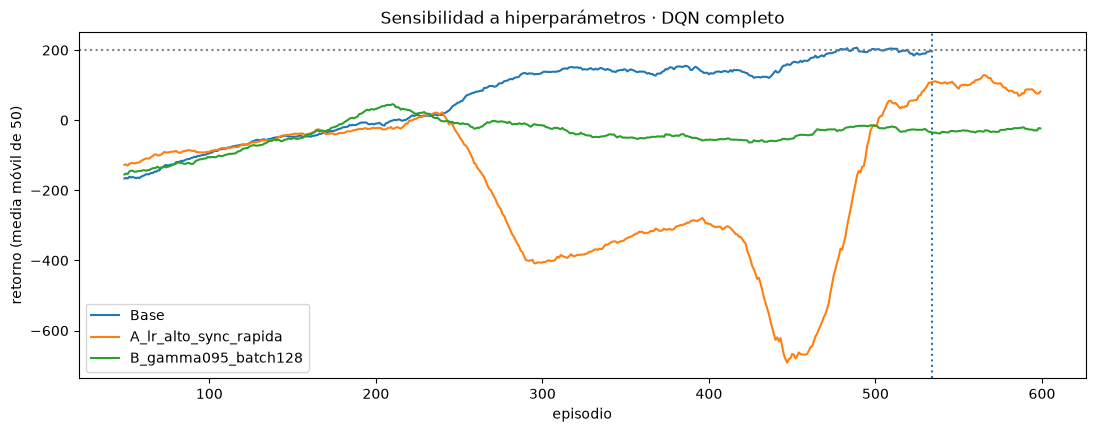

,Configuración,Episodio de convergencia,Mejor media de 50,Desvío del retorno (últimos 100),Episodios de la corrida,Minutos de la corrida
0,Base,534,206.7,121.6,534,7.8
1,A_lr_alto_sync_rapida,no convergió en 600,128.7,153.6,600,6.1
2,B_gamma095_batch128,no convergió en 600,45.9,68.6,600,15.8


In [17]:
MAX_EPISODIOS_SENSIBILIDAD = 3 if SMOKE else 600
configs_sensibilidad = {
    "A_lr_alto_sync_rapida": {"lr": 2.5e-3, "sincronizar_cada": 250},
    "B_gamma095_batch128": {"gamma": 0.95, "batch_size": 128},
}
resultados_sensibilidad = {"Base": (red_completa, estado_completo)}
for nombre, cambio in configs_sensibilidad.items():
    resultados_sensibilidad[nombre] = entrenar_dqn(f"dqn_{nombre}", {**CONFIG_DQN, **cambio},
                                                   MAX_EPISODIOS_SENSIBILIDAD, umbral=200)

fig, eje = plt.subplots(figsize=(13, 4.5))
filas = []
for nombre, (_, estado) in resultados_sensibilidad.items():
    tramo = np.array(estado["historia"]["retorno"][:MAX_EPISODIOS_SENSIBILIDAD])
    linea, = eje.plot(media_movil(tramo, 50), label=nombre)
    convergencia = episodio_umbral(tramo, umbral=200, ventana=100)
    if convergencia:
        eje.axvline(convergencia, color=linea.get_color(), ls=":")
    filas.append({"Configuración": nombre,
                  "Episodio de convergencia": convergencia or f"no convergió en {len(tramo)}",
                  "Mejor media de 50": round(float(np.nanmax(media_movil(tramo, 50))), 1) if len(tramo) >= 50 else None,
                  "Desvío del retorno (últimos 100)": round(float(tramo[-100:].std()), 1),
                  # El tiempo es de toda la corrida: la base puede tener más episodios que A y B
                  "Episodios de la corrida": estado["episodio"],
                  "Minutos de la corrida": round(estado["segundos"] / 60, 1)})
eje.axhline(200, color="gray", ls=":")
eje.set_xlabel("episodio")
eje.set_ylabel("retorno (media móvil de 50)")
eje.set_title("Sensibilidad a hiperparámetros · DQN completo")
eje.legend()
fig.savefig(carpeta_figuras / "ej3_03_sensibilidad.png", dpi=120, bbox_inches="tight")
plt.show()
pd.DataFrame(filas)

**b) ¿Cómo afectó cada parámetro a la velocidad de convergencia y a la
estabilidad?**

> **Resultado.**

| Configuración | Convergencia | Mejor media de 50 | Desvío (últimos 100) | Pasos medios (últimos 100) | Episodios con 1 000 pasos | Minutos |
|---|---|---|---|---|---|---|
| Base | episodio 534 | 206.7 | 121.6 | 395 | 5 % | 7.8 |
| A: lr × 5, copia cada 250 | no en 600 | 128.7 | 153.6 | 446 | 8 % | 6.1 |
| B: γ = 0.95, batch 128 | no en 600 | 45.9 | 68.6 | 973 | 88 % | 15.8 |

**Configuración A.** Hasta el episodio 230 las curvas de A y de la base son casi
iguales: un lr mayor no aprende más rápido. Después A colapsa. La media de 50 cae
a −400 en el episodio 290 y a −680 en el episodio 450. Después se recupera hasta
+130 cerca del episodio 570, pero no converge. Los pasos de optimización son 5
veces más grandes, y la target network se copia 4 veces más seguido. El objetivo
casi sigue a la red online, como en la versión (b). La combinación devuelve el
*moving target* y produce olvido catastrófico. A es la configuración más
inestable (desvío 153.6).

**Configuración B.** La media de 50 queda entre −50 y 0 desde el episodio 200. El
88 % de los últimos 100 episodios llega al límite de 1 000 pasos: el agente
aprendió a flotar. Con γ = 0.95, el horizonte efectivo es $1/(1-\gamma) = 20$
pasos. El +100 del aterrizaje llega cientos de pasos después, y vale
$0.95^{100} \approx 0.006$ veces su valor. El agente no lo ve. Solo ve el shaping
inmediato, que premia no caer, y paga el combustible de flotar. B tiene el menor
desvío (68.6), pero es estable en una política mala. Es también la corrida más
lenta: los episodios son largos y cada paso optimiza un batch del doble de
tamaño.

Cada configuración cambia dos parámetros, así que no se puede separar el efecto
de cada uno. El efecto de γ en B es claro por el mecanismo del horizonte. El
batch de 128 solo reduce el ruido del gradiente, y no explica el vuelo.

## 4. Resumen para el Ejercicio 4

La tabla junta los números de los Ejercicios 2 y 3 que usa la tabla comparativa
del informe (sección 4.1).

In [18]:
resumen = pd.DataFrame({
    "Taxi-v3 · Q-Learning": {
        "Espacio de estados": "discreto, 500 estados",
        "Política": "Q-Table de 500 × 6 (3 000 valores)",
        "Episodios hasta convergencia": f"{episodio_umbral(historia_defecto['exito'])} (éxito ≥ 90 % en 100)",
        "Pasos del entorno": int(historia_defecto["pasos"].sum()),
        "Tiempo de entrenamiento": f"{resultados_taxi['Defecto'][2]:.0f} s ({CONFIG_Q['n_episodios']} episodios)",
    },
    "LunarLander-v3 · DQN": {
        "Espacio de estados": "continuo, 8 dimensiones",
        "Política": f"red 8-128-128-4 ({sum(p.numel() for p in red_completa.parameters()):,} parámetros)",
        "Episodios hasta convergencia": f"{episodio_convergencia or 'no convergió'} (media de 100 ≥ 200)",
        "Pasos del entorno": estado_completo["pasos"],
        "Tiempo de entrenamiento": f"{estado_completo['segundos'] / 60:.0f} min",
    },
})
resumen.to_csv(carpeta_figuras / "ej4_resumen.csv")
resumen

,Taxi-v3 · Q-Learning,LunarLander-v3 · DQN
Espacio de estados,"discreto, 500 estados","continuo, 8 dimensiones"
Política,Q-Table de 500 × 6 (3 000 valores),"red 8-128-128-4 (18,180 parámetros)"
Episodios hasta convergencia,459 (éxito ≥ 90 % en 100),534 (media de 100 ≥ 200)
Pasos del entorno,118863,238293
Tiempo de entrenamiento,2 s (3000 episodios),8 min


> **Resultado.**

- Taxi converge en 459 episodios y 118 863 pasos, en 2 segundos.
- LunarLander converge en 534 episodios y 238 293 pasos, en 8 minutos.
- La cantidad de episodios es parecida, pero cada paso del DQN cuesta mucho más:
  una pasada de la red y un paso de optimización con un batch de 64. El tiempo
  total es 240 veces mayor.

## 5. Conclusiones

- **Taxi.** Q-Learning tabular resuelve Taxi en 459 episodios. La política greedy
  resuelve 99 % de los episodios nuevos. Las recompensas alternativas casi no
  cambian la velocidad, porque ε domina. El shaping por distancia (R1) da la mejor
  política greedy (100 %). Las penalizaciones dobles (R2) dejan más estados con la
  tabla sin converger.
- **Q-Table congelada.** Una política greedy puede quedar en un bucle en estados
  poco visitados. El éxito de entrenamiento (100 %) no alcanza para medir la
  política final.
- **LunarLander.** Una Q-Table con bins no es viable: $10^8$ estados con
  $k = 10$. El DQN completo converge en 534 episodios.
- **Ablación.** El Experience Replay quita la correlación de las muestras y hace
  posible el aprendizaje: de −83 a 99. La target network quita el *moving
  target*: la loss baja de 3 529 a 9, y el retorno sube a 140.
- **Sensibilidad.** Un lr alto con copias frecuentes de la target network
  desestabiliza el entrenamiento. Un γ bajo acorta el horizonte, y el agente no
  ve la recompensa del aterrizaje: aprende a flotar.